<a href="https://colab.research.google.com/github/trantrunghieu26041809-sys/Computer-Vision/blob/main/Binary%20Classification/Computer_Vison_with_TensorFlow_Part1_Binary_Class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bài 1: Tải tập dữ liệu ảnh đầu tiên và cách giải nén

In [ ]:
import zipfile

!wget https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip

# Giải nén file

zip_ref = zipfile.ZipFile("pizza_steak.zip")
zip_ref.extractall()
zip_ref.close()

--2026-10-22 13:58:40--  https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.2.207, 142.250.141.207, 74.125.137.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.2.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 109540975 (104M) [application/zip]
Saving to: ‘pizza_steak.zip’

pizza_steak.zip     100%[===================>] 104.47M  83.4MB/s    in 1.3s    

2026-10-22 13:58:41 (83.4 MB/s) - ‘pizza_steak.zip’ saved [109540975/109540975]



In [ ]:
# Kiểm tra dữ liệu

!ls pizza_steak

!ls pizza_steak/train/

!ls pizza_steak/train/steak

test  train
pizza  steak
1000205.jpg  1647351.jpg  2238681.jpg  2824680.jpg  3375959.jpg  417368.jpg
100135.jpg   1650002.jpg  2238802.jpg  2825100.jpg  3381560.jpg  4176.jpg
101312.jpg   165639.jpg   2254705.jpg  2826987.jpg  3382936.jpg  42125.jpg
1021458.jpg  1658186.jpg  225990.jpg   2832499.jpg  3386119.jpg  421476.jpg
1032846.jpg  1658443.jpg  2260231.jpg  2832960.jpg  3388717.jpg  421561.jpg
10380.jpg    165964.jpg   2268692.jpg  285045.jpg   3389138.jpg  438871.jpg
1049459.jpg  167069.jpg   2271133.jpg  285147.jpg   3393547.jpg  43924.jpg
1053665.jpg  1675632.jpg  227576.jpg   2855315.jpg  3393688.jpg  440188.jpg
1068516.jpg  1678108.jpg  2283057.jpg  2856066.jpg  3396589.jpg  442757.jpg
1068975.jpg  168006.jpg   2286639.jpg  2859933.jpg  339891.jpg	 443210.jpg
1081258.jpg  1682496.jpg  2287136.jpg  286219.jpg   3417789.jpg  444064.jpg
1090122.jpg  1684438.jpg  2291292.jpg  2862562.jpg  3425047.jpg  444709.jpg
1093966.jpg  168775.jpg   229323.jpg   2865730.jpg  3434983.jpg  447

Bài 2: Cách kiểm tra dữ liệu bên trong thư mục

In [ ]:
import os

# Duyệt qua thư mục pizza_steak và kiểm tra số lượng files bên trong

for dirpath, dirnames, filenames in os.walk("pizza_steak"):
  print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")


There are 2 directories and 0 images in 'pizza_steak'.
There are 2 directories and 0 images in 'pizza_steak/test'.
There are 0 directories and 250 images in 'pizza_steak/test/pizza'.
There are 0 directories and 250 images in 'pizza_steak/test/steak'.
There are 2 directories and 0 images in 'pizza_steak/train'.
There are 0 directories and 750 images in 'pizza_steak/train/pizza'.
There are 0 directories and 750 images in 'pizza_steak/train/steak'.


In [ ]:
# Dùng để liệt kê danh sách tệp và thư mục con bên trong pizza_steak ở chế độ chi tiết và hiển thị cả các tệp ẩn

!ls -la pizza_steak

total 16
drwxr-xr-x 4 root root 4096 Oct 22 13:58 .
drwxr-xr-x 1 root root 4096 Oct 22 13:58 ..
drwxr-xr-x 4 root root 4096 Oct 22 13:58 test
drwxr-xr-x 4 root root 4096 Oct 22 13:58 train


In [ ]:
# Cách khác để đếm xem có bao nhiêu tấm ảnh trong file

num_steak_images_train = len(os.listdir("pizza_steak/train/steak"))
num_steak_images_train

750

In [ ]:
# Cách sắp xếp tên thư mục (theo đúng bảng chữ cái)

import pathlib

import numpy as np

data_dir = pathlib.Path("pizza_steak/train")
class_names = np.array(sorted (item.name for item in data_dir.glob("*")))
print(class_names)

['pizza' 'steak']


Bài 3: Chọn ngẫu nhiên 1 ảnh và hiển thị

Image shape: (512, 382, 3)


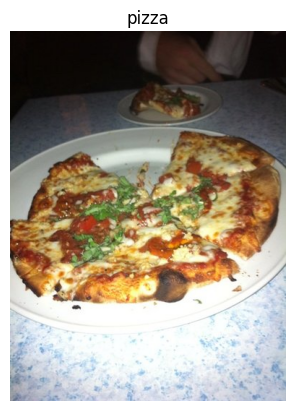

In [ ]:
# Trực quan hóa hình ảnh

import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def view_random_image(target_dir, target_class):
    # Ghép đường dẫn thư mục đích
    target_folder = target_dir + "/" + target_class

    # Chọn ngẫu nhiên 1 ảnh
    random_image = random.sample(os.listdir(target_folder), 1)

    # Đọc ảnh và hiển thị ảnh bằng matplotlib
    img = mpimg.imread(target_folder + "/" + random_image[0])
    plt.imshow(img)
    plt.title(target_class)
    plt.axis("off")

    print(f"Image shape: {img.shape}")  # In kích thước ảnh

    return img

# In ra bức ảnh đã random từ dataset

img = view_random_image(target_dir = "pizza_steak/train", target_class = "pizza")






In [ ]:
import tensorflow as tf
tf.constant(img)

<tf.Tensor: shape=(512, 382, 3), dtype=uint8, numpy=
array([[[ 10,   6,   3],
        [ 10,   6,   3],
        [ 10,   6,   3],
        ...,
        [ 16,   7,   8],
        [ 14,   8,   8],
        [ 14,   8,   8]],

       [[  9,   5,   2],
        [  9,   5,   2],
        [  9,   5,   2],
        ...,
        [ 15,   6,   7],
        [ 13,   7,   7],
        [ 12,   6,   6]],

       [[  9,   5,   2],
        [  9,   5,   2],
        [  9,   5,   2],
        ...,
        [ 12,   6,   6],
        [ 11,   5,   5],
        [ 11,   5,   5]],

       ...,

       [[159, 159, 167],
        [150, 153, 162],
        [153, 157, 168],
        ...,
        [186, 195, 212],
        [183, 192, 207],
        [179, 188, 203]],

       [[152, 155, 162],
        [151, 154, 163],
        [153, 157, 168],
        ...,
        [184, 196, 212],
        [183, 192, 207],
        [178, 187, 202]],

       [[143, 146, 153],
        [148, 151, 160],
        [151, 155, 166],
        ...,
        [183, 195, 21

In [ ]:
img.shape # In ra Width, height và colour channels

(512, 382, 3)

In [ ]:
img/255.

array([[[0.03921569, 0.02352941, 0.01176471],
        [0.03921569, 0.02352941, 0.01176471],
        [0.03921569, 0.02352941, 0.01176471],
        ...,
        [0.0627451 , 0.02745098, 0.03137255],
        [0.05490196, 0.03137255, 0.03137255],
        [0.05490196, 0.03137255, 0.03137255]],

       [[0.03529412, 0.01960784, 0.00784314],
        [0.03529412, 0.01960784, 0.00784314],
        [0.03529412, 0.01960784, 0.00784314],
        ...,
        [0.05882353, 0.02352941, 0.02745098],
        [0.05098039, 0.02745098, 0.02745098],
        [0.04705882, 0.02352941, 0.02352941]],

       [[0.03529412, 0.01960784, 0.00784314],
        [0.03529412, 0.01960784, 0.00784314],
        [0.03529412, 0.01960784, 0.00784314],
        ...,
        [0.04705882, 0.02352941, 0.02352941],
        [0.04313725, 0.01960784, 0.01960784],
        [0.04313725, 0.01960784, 0.01960784]],

       ...,

       [[0.62352941, 0.62352941, 0.65490196],
        [0.58823529, 0.6       , 0.63529412],
        [0.6       , 0

Bài 4: Cách xây dựng mạng noron (CNN)

In [ ]:
# Cách xây dựng mạng noron (CNN)
# Xây dựng mô hình đầu tiên (model_1)
# Thiết lập công cụ tiền xử lý dữ liệu ảnh tự động trước khi đưa vào mô hình
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Thiết lập seed để cố định kết quả ngẫu nhiên
tf.random.set_seed(42)

# Tiền xử lý dữ liệu: chuẩn hóa giá trị pixel về đoạn [0, 1]
train_datagen = ImageDataGenerator(rescale=1./255)
valid_datagen = ImageDataGenerator(rescale=1./255)

# Đường dẫn thư mục
train_dir = "/content/pizza_steak/train"
test_dir = "/content/pizza_steak/test"

# Nạp dữ liệu train và chia thành từng batch
train_data = train_datagen.flow_from_directory(
    directory=train_dir,
    batch_size=32,
    target_size=(224, 224),
    class_mode="binary",
    seed=42
)

# Nạp dữ liệu validation/test tương ứng
valid_data = valid_datagen.flow_from_directory(
    directory=test_dir,
    batch_size=32,
    target_size=(224, 224),
    class_mode="binary",
    seed=42
)

# Xây dựng mô hình CNN (dựa trên kiến trúc Tiny VGG)
model_1 = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(
        filters=10,                         # 10 bộ lọc
        kernel_size=3,                      # Kích thước ma trận bộ lọc là 3x3 pixel
        activation="relu",                  # Hàm kích hoạt ReLU
        input_shape=(224, 224, 3)
    ),
    tf.keras.layers.Conv2D(10, 3, activation="relu"),
    tf.keras.layers.MaxPool2D(pool_size=2, padding="valid"),
    tf.keras.layers.Conv2D(10, 3, activation="relu"),
    tf.keras.layers.Conv2D(10, 3, activation="relu"),
    tf.keras.layers.MaxPool2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Biên dịch mạng noron (CNN)
model_1.compile(
    loss="binary_crossentropy",              # Hàm đo độ sai lệch cho phân loại nhị phân
    optimizer=tf.keras.optimizers.Adam(),   # Thuật toán tối ưu hóa
    metrics=["accuracy"]                    # Theo dõi độ chính xác
)

# Huấn luyện mô hình
history_1 = model_1.fit(
    train_data,                             # Băng chuyền dữ liệu huấn luyện
    epochs=5,                               # Học lặp lại 5 chu kỳ
    steps_per_epoch=len(train_data),        # Số lượt duyệt batch trong 1 epoch
    validation_data=valid_data,
    validation_steps=len(valid_data)
)

len(train_data)

Found 1500 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 342ms/step - accuracy: 0.6693 - loss: 0.5908 - val_accuracy: 0.7240 - val_loss: 0.5020
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 146ms/step - accuracy: 0.7873 - loss: 0.4681 - val_accuracy: 0.8040 - val_loss: 0.4224
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 154ms/step - accuracy: 0.8227 - loss: 0.4076 - val_accuracy: 0.8420 - val_loss: 0.3378
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 154ms/step - accuracy: 0.8240 - loss: 0.3946 - val_accuracy: 0.8600 - val_loss: 0.3429
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 153ms/step - accuracy: 0.8627 - loss: 0.3461 - val_accuracy: 0.8740 - val_loss: 0.3138


47

<Axes: title={'center': 'Đồ thị huấn luyện Model 1'}>

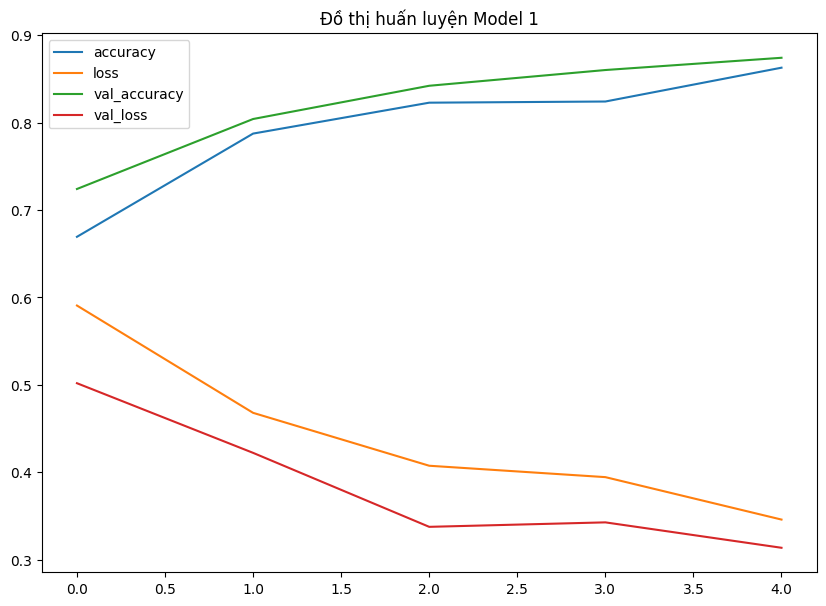

In [ ]:
import pandas as pd
pd.DataFrame(history_1.history).plot(figsize=(10, 7), title="Đồ thị huấn luyện Model 1")

Bài 4 (tiếp theo): Thử sử dụng mạng noron truyền thống mà không dùng mạng tích chập

In [ ]:
# Sử dụng cùng 1 mô hình như trước
# Thử không dùng mạng tích chập mà chỉ dùng mạng nơ-ron truyền thống dạng kết nối đầy đủ thì có phân biệt được pizza với steak không

import tensorflow as tf

# Cố định giá trị ngẫu nhiên để đảm bảo tính tái lập (reproducibility)
tf.random.set_seed(42)

# Xây dựng mô hình phỏng theo TensorFlow Playground (mạng nơ-ron truyền thống / Dense)
model_2 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(224, 224, 3)), # Duỗi phẳng ma trận ảnh 224x224x3 thành vector 150.528 phần tử
    tf.keras.layers.Dense(4, activation="relu"),         # Tầng ẩn 1 với 4 nơ-ron
    tf.keras.layers.Dense(4, activation="relu"),         # Tầng ẩn 2 với 4 nơ-ron
    tf.keras.layers.Dense(1, activation="sigmoid")       # Tầng đầu ra phân loại nhị phân (xác suất 0 đến 1)
])

# Biên dịch mô hình
model_2.compile(
    loss="binary_crossentropy",                          # Hàm mất mát cho bài toán nhị phân
    optimizer=tf.keras.optimizers.Adam(),               # Thuật toán tối ưu Adam
    metrics=["accuracy"]                                # Thước đo độ chính xác
)

# Huấn luyện mô hình
history_2 = model_2.fit(
    train_data,                                         # Dữ liệu tập huấn luyện
    epochs=5,                                           # Huấn luyện qua 5 chu kỳ
    steps_per_epoch=len(train_data),                    # Số bước mỗi epoch
    validation_data=valid_data,                         # Dữ liệu tập kiểm tra để đánh giá song song
    validation_steps=len(valid_data)                    # Số bước kiểm tra mỗi epoch
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 174ms/step - accuracy: 0.5167 - loss: 0.9010 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 145ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 136ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6932


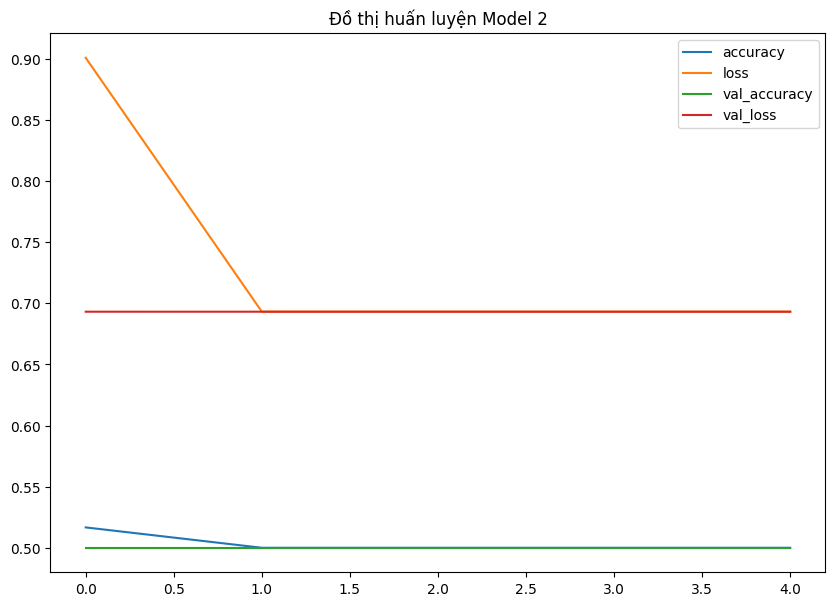

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Vẽ đồ thị từ lịch sử huấn luyện của model_2
pd.DataFrame(history_2.history).plot(figsize=(10, 7))
plt.title("Đồ thị huấn luyện Model 2")
plt.show()

Bài 4 (tiếp theo): Cách để cải thiện mạng noron truyền thống (bằng cách tăng số lượng mạng noron)

In [ ]:
import tensorflow as tf

# 1. Cố định giá trị ngẫu nhiên
tf.random.set_seed(42)

# 2. Xây dựng mô hình model_3 (nâng cấp thêm tầng và nơ-ron)
model_3 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(224, 224, 3)), # Duỗi phẳng ảnh 224x224x3
    tf.keras.layers.Dense(100, activation="relu"),       # Tầng ẩn 1: 100 nơ-ron
    tf.keras.layers.Dense(100, activation="relu"),       # Tầng ẩn 2: 100 nơ-ron
    tf.keras.layers.Dense(100, activation="relu"),       # Tầng ẩn 3: 100 nơ-ron
    tf.keras.layers.Dense(1, activation="sigmoid")       # Tầng đầu ra phân loại nhị phân
])

# 3. Biên dịch mô hình
model_3.compile(
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"]
)

# 4. Huấn luyện mô hình qua 5 epochs
history_3 = model_3.fit(
    train_data,
    epochs=5,
    steps_per_epoch=len(train_data),
    validation_data=valid_data,
    validation_steps=len(valid_data)
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 188ms/step - accuracy: 0.5553 - loss: 5.5353 - val_accuracy: 0.6520 - val_loss: 1.2631
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 141ms/step - accuracy: 0.7060 - loss: 0.6665 - val_accuracy: 0.7400 - val_loss: 0.5413
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.6940 - loss: 0.6814 - val_accuracy: 0.7260 - val_loss: 0.5979
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 136ms/step - accuracy: 0.7673 - loss: 0.5066 - val_accuracy: 0.7540 - val_loss: 0.5099
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.7427 - loss: 0.5887 - val_accuracy: 0.7740 - val_loss: 0.5076


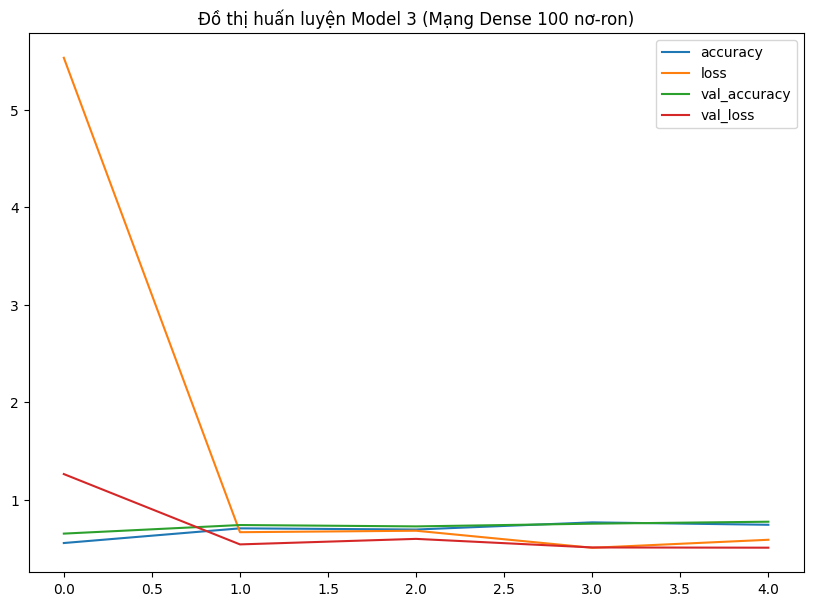

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Vẽ đồ thị từ lịch sử huấn luyện của model_3
pd.DataFrame(history_3.history).plot(figsize=(10, 7))
plt.title("Đồ thị huấn luyện Model 3 (Mạng Dense 100 nơ-ron)")
plt.show()

Bài 5: Tìm hiểu sâu về mạng CNN (phần 1)
1. Become one with the data (Hòa làm một với dữ liệu)
2. Preprocess the data (Tiền xử lý dữ liệu)
3. Created a model (Xây dựng mô hình cơ sở - Baseline)
4. Fit the model (Huấn luyện mô hình)
5. Evaluate the model (Đánh giá mô hình)
6. Adjust different parameters and improve the model (Tinh chỉnh tham số)
7. Repeat until satisfied (Lặp lại cho đến khi hài lòng)

1. Become one with the data (Hòa làm một với dữ liệu)

Image shape: (512, 512, 3)
Image shape: (289, 512, 3)


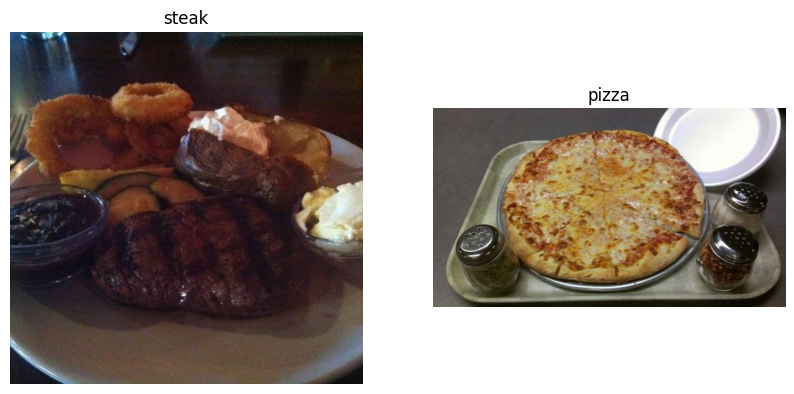

In [ ]:
# Visualize data (Trực quan hóa dữ liệu)
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7)) # Tạo khung vẽ

# Ô bên trái: 1 hàng, 2 cột, vị trí 1
plt.subplot(1, 2, 1)
steak_img = view_random_image("pizza_steak/train/", "steak")

# Ô bên phải: 1 hàng, 2 cột, vị trí 2
plt.subplot(1, 2, 2)
pizza_img = view_random_image("pizza_steak/train/", "pizza")

Bài 5: Tìm hiểu sâu về mạng CNN (phần 2)

1. Chuẩn bị dữ liệu (prepare data for a model)

Bước tiếp theo của chúng ta là chia dữ liệu thành các batch (từng mẻ/nhóm nhỏ).

Một batch là một tập con nhỏ của dữ liệu. Thay vì nhìn vào toàn bộ khoảng ~10.000 bức ảnh cùng một lúc, mô hình có thể chỉ nhìn 32 ảnh ở mỗi lượt.

Việc làm này xuất phát từ một vài lý do:

1. 10.000 bức ảnh (hoặc nhiều hơn) có thể sẽ không nhét vừa vào bộ nhớ của bộ xử lý (GPU).

2. Cố gắng học các mẫu hình (patterns) trong 10.000 bức ảnh chỉ trong một lần duy nhất có thể dẫn đến việc mô hình học không được tốt lắm.

Tại sao lại là con số 32?

Bởi vì con số 32 tốt cho sức khỏe của bạn...

In [ ]:
!nvidia-smi


Thu Oct 22 14:01:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P0             27W /   70W |    1151MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Create train and test data generators and rescale the data
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1/255.)
test_datagen = ImageDataGenerator(rescale=1/255.)

In [ ]:
# Load in our image data from directories and turn them into batches
train_data = train_datagen.flow_from_directory(
    directory=train_dir,
    target_size=(224, 224),
    class_mode="binary",
    batch_size=32
)

test_data = test_datagen.flow_from_directory(
    directory=test_dir,
    target_size=(224, 224),
    class_mode="binary",
    batch_size=32
)

Found 1500 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


In [ ]:
# Lấy mẫu một mẻ (batch) dữ liệu từ tập huấn luyện theo chuẩn Python mới
images, labels = next(
    train_data
)  # Lấy mẻ ảnh và nhãn tiếp theo trên băng chuyền train_data

# Kiểm tra số lượng ảnh và số lượng nhãn trong mẻ này
len(images), len(labels)

(32, 32)

In [ ]:
len(train_data)

47

In [ ]:
# Lấy 2 tấm ảnh đầu tiên
images[:-2], images[0].shape

(array([[[[0.56078434, 0.63529414, 0.79215693],
          [0.5647059 , 0.6392157 , 0.7960785 ],
          [0.5647059 , 0.6392157 , 0.80392164],
          ...,
          [0.07843138, 0.08235294, 0.05882353],
          [0.08235294, 0.08235294, 0.07450981],
          [0.09803922, 0.09803922, 0.09803922]],
 
         [[0.5647059 , 0.6392157 , 0.7960785 ],
          [0.5568628 , 0.6313726 , 0.7960785 ],
          [0.5568628 , 0.6313726 , 0.7960785 ],
          ...,
          [0.09803922, 0.10196079, 0.07058824],
          [0.0627451 , 0.06666667, 0.04705883],
          [0.04313726, 0.04313726, 0.03529412]],
 
         [[0.5686275 , 0.6431373 , 0.8078432 ],
          [0.5647059 , 0.6392157 , 0.80392164],
          [0.5647059 , 0.6392157 , 0.8078432 ],
          ...,
          [0.07450981, 0.07843138, 0.04705883],
          [0.15686275, 0.16078432, 0.13725491],
          [0.21568629, 0.21960786, 0.20000002]],
 
         ...,
 
         [[0.3921569 , 0.34901962, 0.22352943],
          [0.39607

Xem cái batch đầu tiên của labels

In [ ]:
labels

array([0., 1., 1., 0., 1., 0., 1., 1., 0., 1., 0., 0., 1., 1., 1., 0., 0.,
       0., 0., 1., 1., 1., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1.],
      dtype=float32)

Bài 6: Cách thiết kế mạng noron CNN (bắt đầu với mô hình cơ sở)

Một mô hình cơ sở (baseline) là một mô hình tương đối đơn giản hoặc một kết quả có sẵn mà bạn thiết lập khi bắt đầu một thử nghiệm học máy; sau đó, trong quá trình tiếp tục thử nghiệm, bạn sẽ cố gắng vượt qua mốc cơ sở đó (beat the baseline).

In [ ]:
# Giúp việc tạo mô hình trở nên dễ dàng và ngắn gọn hơn
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPool2D, Activation
from tensorflow.keras import Sequential

# Tạo mô hình cơ sở model_4 (mạng nơ-ron tích chập không có MaxPool)
model_4 = Sequential([
    # Tầng tích chập 1: viết chi tiết từng tham số kèm input_shape
    Conv2D(
        filters=10,
        kernel_size=3,
        strides=(1, 1),
        padding="same",  # Nếu dùng "same" thì kích thước đầu ra sẽ bằng kích thước đầu vào
        activation="relu",
        input_shape=(224, 224, 3),  # Tầng đầu vào: kích thước ảnh 224x224x3
    ),
    # Tầng tích chập 2: viết dạng rút gọn (10 filters, kernel 3x3)
    Conv2D(10, 3, activation="relu"),
    # Tầng tích chập 3: viết dạng rút gọn
    Conv2D(10, 3, activation="relu"),
    # Tầng duỗi phẳng: biến ma trận đặc trưng 3D thành vector 1D
    Flatten(),
    # Tầng đầu ra: 1 nơ-ron phân loại nhị phân (xác suất Pizza hay Steak)
    Dense(1, activation="sigmoid"),
])

# Biên dịch mô hình model_4
model_4.compile(
    loss="binary_crossentropy",  # Hàm mất mát cho bài toán phân loại nhị phân (2 lớp)
    optimizer=Adam(),  # Thuật toán tối ưu Adam (đã import ở ô trên)
    metrics=["accuracy"],  # Theo dõi độ chính xác trong quá trình học
)

# Huấn luyện mô hình model_4 qua 5 epochs
history_4 = model_4.fit(
    train_data,  # Dữ liệu tập huấn luyện (chia theo batch 32)
    epochs=5,  # Học lặp lại 5 chu kỳ
    steps_per_epoch=len(train_data),  # Số batch trong 1 epoch (47 batches)
    validation_data=valid_data,  # Dữ liệu tập kiểm tra để đánh giá song song
    validation_steps=len(valid_data),  # Số batch kiểm tra mỗi epoch
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 277ms/step - accuracy: 0.6667 - loss: 0.8539 - val_accuracy: 0.7480 - val_loss: 0.4826
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.7893 - loss: 0.4630 - val_accuracy: 0.8080 - val_loss: 0.4302
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.8707 - loss: 0.3254 - val_accuracy: 0.8100 - val_loss: 0.3861
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 151ms/step - accuracy: 0.9360 - loss: 0.1920 - val_accuracy: 0.8560 - val_loss: 0.3403
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 140ms/step - accuracy: 0.9773 - loss: 0.0900 - val_accuracy: 0.7820 - val_loss: 0.4973


Bài 7: Cách đánh giá mô hình

<Axes: >

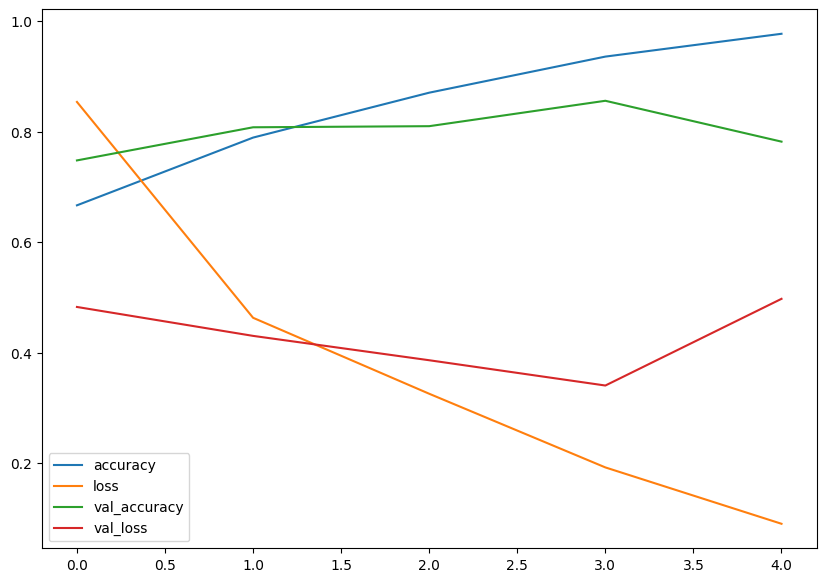

In [ ]:
# Vẽ các đường cong huấn luyện (training curves)
import pandas as pd

pd.DataFrame(history_4.history).plot(figsize=(10, 7))

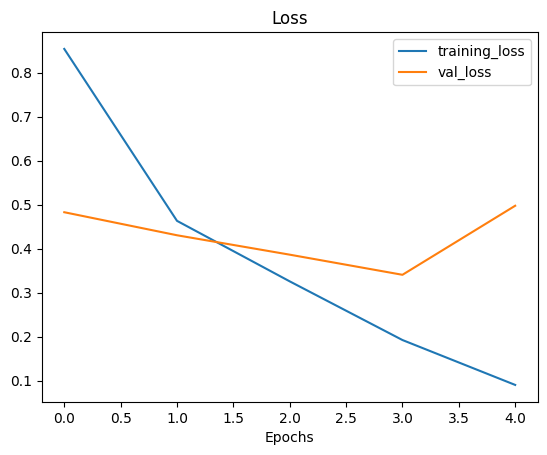

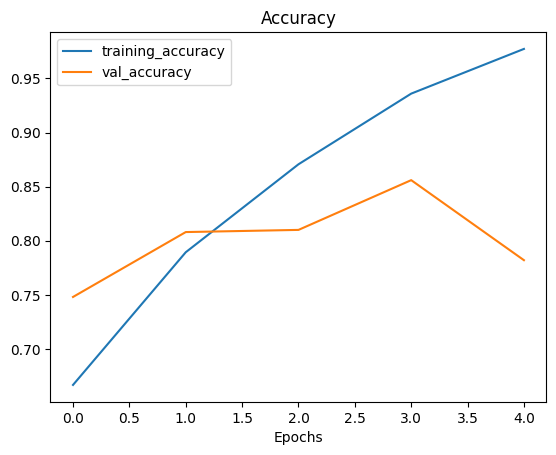

In [ ]:
import matplotlib.pyplot as plt


# Hàm vẽ riêng biệt hai đường cong huấn luyện và kiểm tra
def plot_loss_curves(history):
  """Trả về các biểu đồ đường cong loss và accuracy riêng biệt."""
  loss = history.history["loss"]
  val_loss = history.history["val_loss"]

  accuracy = history.history["accuracy"]
  val_accuracy = history.history["val_accuracy"]

  epochs = range(len(history.history["loss"]))  # Xác định số epoch đã chạy

  # 1. Vẽ biểu đồ Loss
  plt.figure()  # Tạo khung hình 1 cho Loss
  plt.plot(epochs, loss, label="training_loss")
  plt.plot(epochs, val_loss, label="val_loss")
  plt.title("Loss")
  plt.xlabel("Epochs")
  plt.legend()

  # 2. Vẽ biểu đồ Accuracy
  plt.figure()  # Tạo khung hình 2 riêng biệt cho Accuracy
  plt.plot(epochs, accuracy, label="training_accuracy")
  plt.plot(epochs, val_accuracy, label="val_accuracy")
  plt.title("Accuracy")
  plt.xlabel("Epochs")
  plt.legend()

plot_loss_curves(history_4)

Quá trình huấn luyện (fitting) một mô hình học máy thường diễn ra qua 3 bước:

0. Tạo một mô hình cơ sở (Create a baseline): Bắt đầu bằng một mô hình đơn giản nhất có thể.

1. Vượt qua mô hình cơ sở bằng cách cho một mô hình lớn hơn "học vẹt" (Beat the baseline by overfitting a larger model).

2. Giảm thiểu hiện tượng học vẹt (Reduce overfitting).

**Các cách để tạo ra hiện tượng học vẹt (Induce Overfitting):**
* Tăng số lượng tầng tích chập (conv layers).
* Tăng số lượng bộ lọc trong mỗi tầng tích chập (conv filters).
* Thêm một tầng dense vào sau tầng duỗi phẳng (flattened layer).

**Các cách để giảm thiểu hiện tượng học vẹt (Reduce Overfitting):**
* Thêm kỹ thuật tăng cường dữ liệu (Data Augmentation).
* Thêm các tầng điều hòa (Regularization layers - chẳng hạn như MaxPool2D).
* Bổ sung thêm nhiều dữ liệu hơn (Add more data...).

In [ ]:
# Tạo mô hình model_5 (baseline mới có bổ sung các tầng MaxPool2D)
model_5 = Sequential([
    Conv2D(10, 3, activation="relu", input_shape=(224, 224, 3)),
    MaxPool2D(pool_size=2),  # Nén kích thước ảnh xuống 1/2
    Conv2D(10, 3, activation="relu"),
    MaxPool2D(),  # Mặc định pool_size=(2, 2)
    Conv2D(10, 3, activation="relu"),
    MaxPool2D(),
    Flatten(),
    Dense(1, activation="sigmoid"),
])

# Biên dịch mô hình
model_5.compile(
    loss="binary_crossentropy", optimizer=Adam(), metrics=["accuracy"]
)

# Huấn luyện mô hình qua 5 epochs
history_5 = model_5.fit(
    train_data,
    epochs=5,
    steps_per_epoch=len(train_data),
    validation_data=valid_data,
    validation_steps=len(valid_data),
)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 17s 262ms/step - accuracy: 0.6293 - loss: 0.6223 - val_accuracy: 0.8140 - val_loss: 0.4489
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 135ms/step - accuracy: 0.7853 - loss: 0.4570 - val_accuracy: 0.8320 - val_loss: 0.3824
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 139ms/step - accuracy: 0.8260 - loss: 0.3984 - val_accuracy: 0.8500 - val_loss: 0.3367
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step - accuracy: 0.8387 - loss: 0.3723 - val_accuracy: 0.8700 - val_loss: 0.3066
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 134ms/step - accuracy: 0.8447 - loss: 0.3498 - val_accuracy: 0.8900 - val_loss: 0.3004


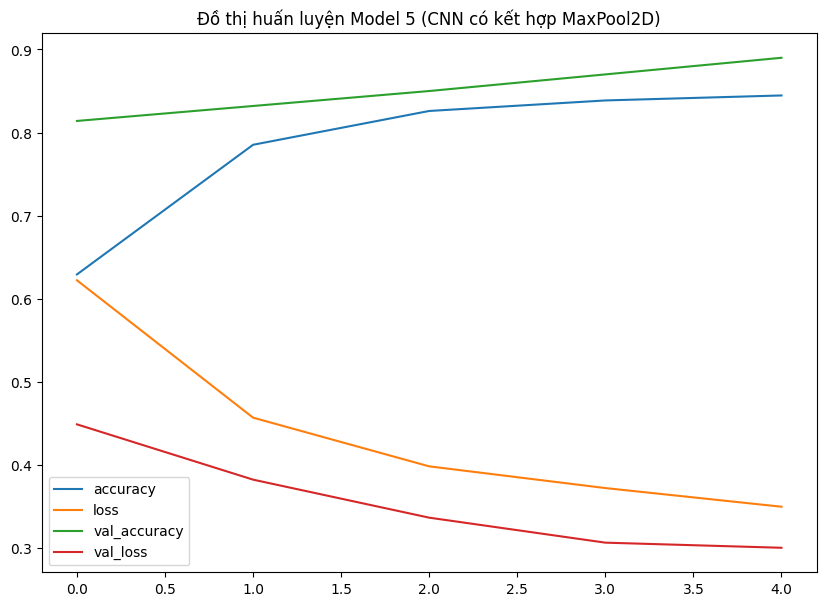

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Vẽ đồ thị từ lịch sử huấn luyện của model_5
pd.DataFrame(history_5.history).plot(figsize=(10, 7))
plt.title("Đồ thị huấn luyện Model 5 (CNN có kết hợp MaxPool2D)")
plt.show()

Bài 21: Cách sửa lỗi học vẹt bằng cách bóp méo, xoay hay lật ảnh

Tăng cường dữ liệu là quá trình làm biến đổi dữ liệu huấn luyện của chúng ta, giúp dữ liệu trở nên đa dạng hơn, và từ đó cho phép mô hình học được các mẫu hình có tính khái quát hóa cao hơn.

Việc làm biến đổi ở đây có thể bao gồm: điều chỉnh góc xoay của bức ảnh, lật ảnh, cắt xén ảnh hoặc các thao tác tương tự.

In [ ]:
# Áp dụng kỹ thuật Tăng cường dữ liệu (Data Augmentation)
train_datagen_augmented = ImageDataGenerator(
    rescale=1 / 255.0,  # Chuẩn hóa giá trị pixel về [0, 1]
    rotation_range=0.2,  # Xoay ngẫu nhiên tối đa 20%
    shear_range=0.2,  # Kéo xiên góc ngẫu nhiên tối đa 20%
    zoom_range=0.2,  # Phóng to/thu nhỏ ngẫu nhiên 20%
    width_shift_range=0.2,  # Dịch chuyển ngang tối đa 20%
    height_shift_range=0.3,  # Dịch chuyển dọc tối đa 30%
    horizontal_flip=True,  # Lật ngang ngẫu nhiên (lật gương)
)

train_datagen = ImageDataGenerator(rescale=1/255.)

test_datagen = ImageDataGenerator(rescale=1/255.)

Bài 22: So sánh ảnh gốc với ảnh sau khi bị "xoay, lật, kéo méo" bằng Data Augmentation

In [ ]:
# 1. Nạp dữ liệu train CÓ tăng cường (Augmented)
print("Dữ liệu huấn luyện có tăng cường:")
train_data_augmented = train_datagen_augmented.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False,  # Tắt xáo trộn để đối chiếu 1-1 với ảnh gốc
)

# 2. Nạp dữ liệu train GỐC KHÔNG tăng cường (Non-augmented)
print("Dữ liệu huấn luyện gốc:")
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False,  # Tắt xáo trộn
)

# 3. Nạp dữ liệu test
IMG_SIZE = (224, 224)
print("Dữ liệu kiểm tra (test):")
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,  # Đã sửa thành target_size
    batch_size=32,
    class_mode="binary",
)

Dữ liệu huấn luyện có tăng cường:
Found 1500 images belonging to 2 classes.
Dữ liệu huấn luyện gốc:
Found 1500 images belonging to 2 classes.
Dữ liệu kiểm tra (test):
Found 500 images belonging to 2 classes.


Lưu ý: Kỹ thuật tăng cường dữ liệu (Data augmentation) thường chỉ được thực hiện trên dữ liệu huấn luyện (training data). Khi sử dụng các tham số tăng cường tích hợp sẵn của ImageDataGenerator, các bức ảnh gốc của chúng ta vẫn được giữ nguyên vẹn trong các thư mục, nhưng sẽ được biến đổi ngay trong lúc chúng được nạp vào mô hình.

Đang hiển thị bức ảnh số: 15


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

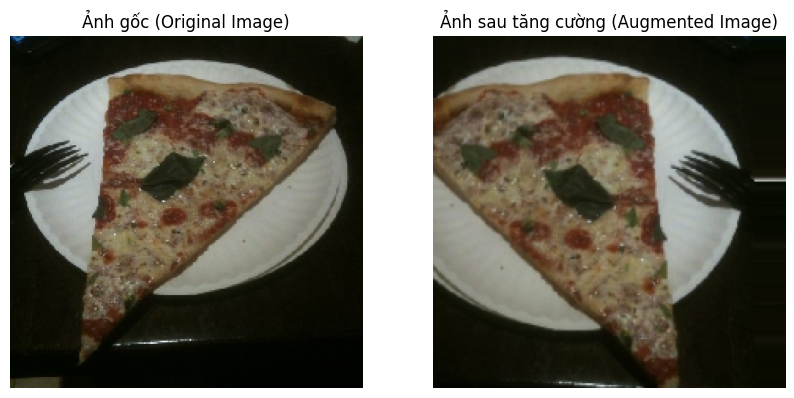

In [ ]:
import random
import matplotlib.pyplot as plt

# 1. Lấy mẻ ảnh đầu tiên từ cả 2 bộ dữ liệu (nhờ shuffle=False nên thứ tự ảnh khớp 1-1)
images, labels = next(train_data)
augmented_images, augmented_labels = next(train_data_augmented)

# 2. Chọn ngẫu nhiên một chỉ số ảnh trong mẻ 32 ảnh (từ 0 đến 31)
random_number = random.randint(0, 31)
print(f"Đang hiển thị bức ảnh số: {random_number}")

# 3. Vẽ hai bức ảnh cạnh nhau
plt.figure(figsize=(10, 5))

# Ô bên trái: Ảnh gốc
plt.subplot(1, 2, 1)
plt.title("Ảnh gốc (Original Image)")
plt.imshow(images[random_number])
plt.axis(False)

# Ô bên phải: Ảnh đã qua tăng cường dữ liệu
plt.subplot(1, 2, 2)
plt.title("Ảnh sau tăng cường (Augmented Image)")
plt.imshow(augmented_images[random_number])
plt.axis(False)

Bài 8: Xây dựng model_6 (có sử dụng train_data_augmented)

In [ ]:
# 1. Khởi tạo kiến trúc mô hình model_6 (giống hệt model_5)
model_6 = Sequential([
    Conv2D(10, 3, activation="relu", input_shape=(224, 224, 3)),
    MaxPool2D(pool_size=2),
    Conv2D(10, 3, activation="relu"),
    MaxPool2D(),
    Conv2D(10, 3, activation="relu"),
    MaxPool2D(),
    Flatten(),
    Dense(1, activation="sigmoid"),
])

# 2. Biên dịch mô hình
model_6.compile(
    loss="binary_crossentropy",
    optimizer=Adam(),
    metrics=["accuracy"],  # Điền nốt ["accuracy"] vào chỗ con trỏ đang gõ dở
)

# 3. Huấn luyện mô hình model_6 VỚI DỮ LIỆU ĐÃ TĂNG CƯỜNG
history_6 = model_6.fit(
    train_data_augmented,  # <--- ĐIỂM KHÁC BIỆT DUY NHẤT: Nạp dữ liệu có xoay/lật ảnh!
    epochs=5,
    steps_per_epoch=len(train_data_augmented),
    validation_data=test_data,
    validation_steps=len(test_data),
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 469ms/step - accuracy: 0.4660 - loss: 0.7054 - val_accuracy: 0.5540 - val_loss: 0.6855
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 436ms/step - accuracy: 0.5733 - loss: 0.6868 - val_accuracy: 0.6800 - val_loss: 0.6647
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 440ms/step - accuracy: 0.5613 - loss: 0.6858 - val_accuracy: 0.6160 - val_loss: 0.6410
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 425ms/step - accuracy: 0.5987 - loss: 0.6608 - val_accuracy: 0.7200 - val_loss: 0.5948
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 461ms/step - accuracy: 0.7020 - loss: 0.7332 - val_accuracy: 0.5460 - val_loss: 0.6507


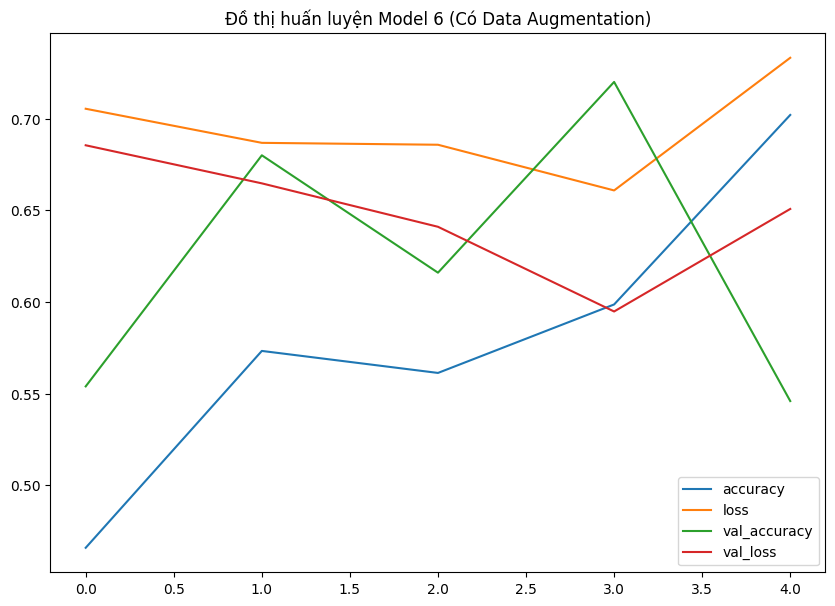

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Vẽ đồ thị từ lịch sử huấn luyện của model_6
pd.DataFrame(history_6.history).plot(figsize=(10, 7))
plt.title("Đồ thị huấn luyện Model 6 (Có Data Augmentation)")
plt.show()

Bài 9: Xây dựng model_7 (có shuffle)


In [ ]:
# Nạp dữ liệu từ thư mục train, áp dụng augmentation và xáo trộn thứ tự ảnh
train_data_augmented_shuffled = train_datagen_augmented.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    class_mode="binary",
    batch_size=32,
    shuffle=True,  # Mặc định trong Keras là True
)

Found 1500 images belonging to 2 classes.


In [ ]:
# 1. Khởi tạo kiến trúc giống hệt model_5 và model_6
model_7 = Sequential([
    Conv2D(10, 3, activation="relu", input_shape=(224, 224, 3)),
    MaxPool2D(),  # Mặc định pool_size=(2, 2)
    Conv2D(10, 3, activation="relu"),
    MaxPool2D(),
    Conv2D(10, 3, activation="relu"),
    MaxPool2D(),
    Flatten(),
    Dense(1, activation="sigmoid"),  # Phân loại nhị phân (pizza vs. steak)
])

# 2. Biên dịch mô hình
model_7.compile(
    loss="binary_crossentropy", optimizer=Adam(), metrics=["accuracy"]
)

# 3. Huấn luyện mô hình trên dữ liệu đã augment và shuffle
history_7 = model_7.fit(
    train_data_augmented_shuffled,
    epochs=5,
    steps_per_epoch=len(train_data_augmented_shuffled),
    validation_data=test_data,
    validation_steps=len(test_data),
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 467ms/step - accuracy: 0.5920 - loss: 0.6723 - val_accuracy: 0.6660 - val_loss: 0.5769
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 437ms/step - accuracy: 0.7247 - loss: 0.5388 - val_accuracy: 0.8400 - val_loss: 0.3671
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 430ms/step - accuracy: 0.7413 - loss: 0.5399 - val_accuracy: 0.8220 - val_loss: 0.4022
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 449ms/step - accuracy: 0.7933 - loss: 0.4691 - val_accuracy: 0.8840 - val_loss: 0.3284
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 436ms/step - accuracy: 0.7747 - loss: 0.4743 - val_accuracy: 0.8480 - val_loss: 0.3694


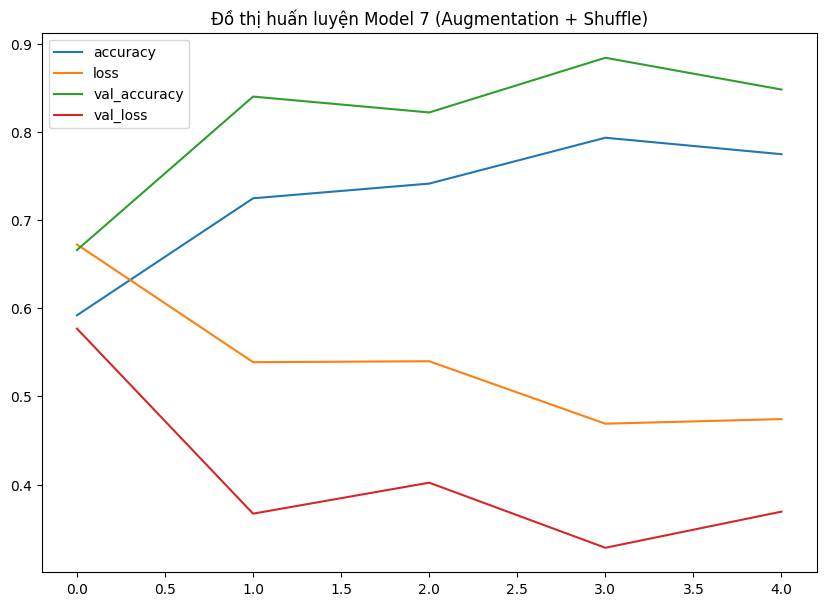

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Vẽ đồ thị từ lịch sử huấn luyện của model_7
pd.DataFrame(history_7.history).plot(figsize=(10, 7))
plt.title("Đồ thị huấn luyện Model 7 (Augmentation + Shuffle)")
plt.show()


Vì chúng ta đã vượt qua được mô hình cơ sở (beaten our baseline), có một vài cách chúng ta có thể thử để tiếp tục cải thiện mô hình của mình:

Tăng số lượng lớp của mô hình (ví dụ: thêm nhiều lớp Conv2D / MaxPool2D hơn).

Tăng số lượng bộ lọc (filters) trong mỗi lớp tích chập (ví dụ: tăng từ 10 lên 32 hoặc thậm chí 64).

Huấn luyện lâu hơn (tăng số lượng epochs).

Tìm tốc độ học (learning rate) lý tưởng.

Thu thập thêm dữ liệu (cho mô hình thêm nhiều cơ hội để học).

Sử dụng học chuyển giao (transfer learning) để tận dụng những gì một mô hình xử lý ảnh khác đã học được và điều chỉnh lại cho bài toán riêng của chúng ta.

Bài 10: Viết một hàm hỗ trợ để nạp và tiền xử lý các bức ảnh tùy chỉnh.

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Hàm tiền xử lý ảnh tự chọn
def load_and_prep_image(filename, img_shape=224):
  # 1. Đọc file ảnh
  img = tf.io.read_file(filename)
  # 2. Giải mã thành ma trận số
  img = tf.image.decode_image(img)
  # 3. Resize về kích thước chuẩn (224, 224)
  img = tf.image.resize(img, [img_shape, img_shape])
  # 4. Ép cân về [0, 1]
  img = img / 255.0
  return img


In [ ]:
# Định nghĩa hàm pred_and_plot để hiển thị % nhận diện
def pred_and_plot(model, filename, class_names):
  # 1. Tải và tiền xử lý ảnh
  img = load_and_prep_image(filename)

  # 2. Dự đoán
  pred = model.predict(tf.expand_dims(img, axis=0))

  # 3. Tính toán nhãn và tỉ lệ phần trăm dựa trên sigmoid (nhị phân)
  pred_prob = pred[0][0] # Lấy giá trị xác suất (từ 0 đến 1)

  if pred_prob >= 0.5:
    pred_class = class_names[1]        # Thường là steak (nhãn index 1)
    confidence = pred_prob * 100        # Độ tin cậy cho lớp steak
  else:
    pred_class = class_names[0]        # Thường là pizza (nhãn index 0)
    confidence = (1 - pred_prob) * 100  # Độ tin cậy cho lớp pizza (ngược lại của steak)

  # 4. Vẽ ảnh và hiển thị kết quả
  plt.imshow(img)
  plt.title(f"Dự đoán: {pred_class} ({confidence:.2f}%)") # In % lên tiêu đề ảnh
  plt.axis(False)
  plt.show()

  # In ra màn hình
  print(f"Ảnh: {filename}")
  print(f"Dự đoán: {pred_class}")
  print(f"Độ tin cậy: {confidence:.2f}%")

Thực chiến với ảnh trên mạng

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


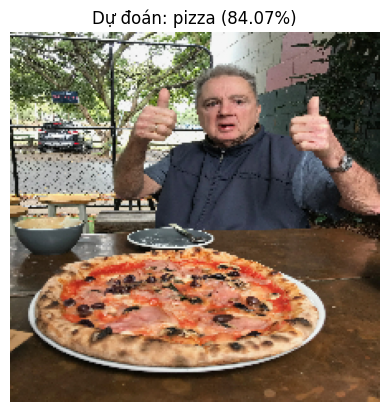

Ảnh: /content/03-pizza-dad (1).jpeg
Dự đoán: pizza
Độ tin cậy: 84.07%


In [ ]:
# Gọi hàm với đúng tên file vừa tải về:
pred_and_plot(
    model=model_7, filename="/content/03-pizza-dad (1).jpeg", class_names=class_names
)

In [ ]:
# Lưu ý: Khi bạn huấn luyện một mạng nơ-ron và muốn dùng nó để đưa ra dự đoán
# trên dữ liệu tùy chỉnh của riêng bạn, điều quan trọng là dữ liệu tùy chỉnh
# (hoặc dữ liệu mới) đó phải được tiền xử lý về cùng một định dạng
# với dữ liệu mà mô hình của bạn đã được huấn luyện

# Tạo một hàm để nhập ảnh và thay đổi kích thước của nó để có thể sử dụng được với mô hình của chúng ta
def load_and_prep_image(filename, img_shape=224):
  """
  Đọc một ảnh từ tên file, chuyển đổi nó thành một tensor và định hình lại thành
  (img_shape, img_shape, colour_channels) (chiều cao, chiều rộng, các kênh màu)
  """
  # Đọc vào bức ảnh[cite: 9]
  img = tf.io.read_file(filename)

  # Giải mã file vừa đọc thành một tensor
  img = tf.image.decode_image(img)

  # Thay đổi kích thước (resize) bức ảnh
  img = tf.image.resize(img, size=[img_shape, img_shape])

  # Nén tấm ảnh
  img = img/255.

  return img


In [ ]:
# Tải và tiền xử lý bức ảnh tùy chỉnh
steak = load_and_prep_image("steak.jpg")
steak

<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
array([[[0.37993696, 0.3877801 , 0.43483892],
        [0.36981794, 0.37766108, 0.4247199 ],
        [0.35344887, 0.361292  , 0.40835083],
        ...,
        [0.14623599, 0.1580007 , 0.17760853],
        [0.15157567, 0.16334037, 0.18294822],
        [0.13447116, 0.14623587, 0.16584371]],

       [[0.37993696, 0.3877801 , 0.43483892],
        [0.37015322, 0.37799636, 0.42505518],
        [0.35537466, 0.3632178 , 0.41027662],
        ...,
        [0.15064634, 0.16241105, 0.18201889],
        [0.1570177 , 0.1687824 , 0.18839024],
        [0.14024846, 0.15201317, 0.17162101]],

       [[0.37699533, 0.38483846, 0.43189728],
        [0.3682234 , 0.37606654, 0.42312536],
        [0.35575745, 0.36360058, 0.4106594 ],
        ...,
        [0.15427639, 0.16604109, 0.18564893],
        [0.16353719, 0.1753019 , 0.19490974],
        [0.14686565, 0.15863036, 0.1782382 ]],

       ...,

       [[0.27638313, 0.28422627, 0.3312851 ],
        [0.28

In [ ]:
pred = model_7.predict(tf.expand_dims(steak, axis=0))
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


array([[0.60547215]], dtype=float32)

In [ ]:
pred_class = class_names[int(tf.round(pred))]
pred_class

np.str_('steak')

In [ ]:
def pred_and_plot(model, filename, class_names=class_names):
  # 1. Tải và tiền xử lý ảnh
  img = load_and_prep_image(filename)

  # 2. Đưa ra dự đoán
  pred = model.predict(tf.expand_dims(img, axis=0))
  pred_prob = pred[0][0]

  # 3. Tính toán nhãn và tỷ lệ %
  if pred_prob >= 0.5:
    pred_class = class_names[1]
    confidence = pred_prob * 100
  else:
    pred_class = class_names[0]
    confidence = (1 - pred_prob) * 100

  # 4. Vẽ ảnh và kết quả
  plt.imshow(img)
  plt.title(f"Dự đoán: {pred_class} ({confidence:.2f}%)")
  plt.axis(False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


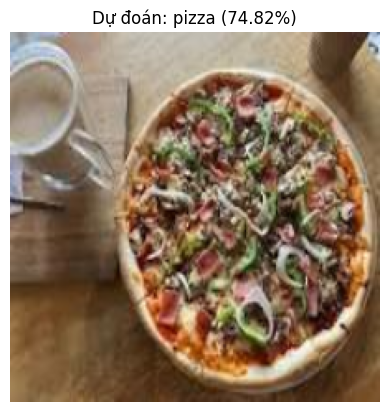

In [ ]:
pred_and_plot(model_7, "/content/pizza.jpg")